# 05 -- Noise correlation: measuring it, and what it costs to ignore

**Goal:** measure whether real MUSE per-pixel noise is actually
independent, as every chi2, AIC criterion, and bootstrap variance
computed anywhere in this package assumes by default -- and show the
practical consequence of getting this wrong, both on real data and on a
synthetic mock with known ground truth.

**Why this matters more than it sounds like it should.** `fit_losvd` and
`bootstrap_losvd` both consume "whitened" inputs (`A_stack_w =
A_stack/errors`, `y_w = flux/errors`) and just compute
`sum(residual**2)` -- correct only if per-pixel noise really is
independent. MUSE spectra are resampled/drizzled onto a regular spatial
grid during pipeline reduction, a well-documented source of pixel-to-
pixel correlation (Bacon et al. 2017); if real pixels are correlated and
treated as independent, every chi2/AIC/bootstrap-variance number in this
package is silently miscalibrated by the same systematic amount.

**Why correlation would look like an AR(1) process, physically.**
Resampling smooths a photon's contribution across its neighboring
*output* pixels (the literal mechanism behind "drizzling" onto a regular
grid from an irregular input sampling) -- so a noise fluctuation at pixel
`i` leaks a little into pixel `i+1`, less into `i+2`, and so on, decaying
with pixel separation. That decaying-with-distance signature is exactly
what an AR(1) model (`Sigma_ij = sigma_i * sigma_j * rho^|i-j|`)
describes. This notebook measures that decay directly rather than
assuming it, on real data (Sections 1-6) and on a synthetic mock built
with a known, injected `rho` (Section 7), where the effect on recovery
can be checked against ground truth directly.

**Roadmap**: load a real spectrum and fit it the way every other
notebook in this sequence does (Sections 1-2) -> measure the actual
pixel correlation in its residual, including a direct look at the
correlation structure itself (Section 3) -> connect that to the
literature (Section 4) -> refit properly accounting for it (Section 5)
-> see what changes, including for the reported uncertainty (Section 6)
-> confirm the whole mechanism against a synthetic mock with known truth
(Section 7).

## Primer: what "AR(1)" means, and how to read a `rho` value

This notebook leans on two ideas that are easy to skim past without
actually knowing what they mean. Both are worth pinning down before
Section 1, since everything below is really just measuring one number
(`rho`) and tracing its consequences.

**A correlation coefficient, in plain terms.** `rho` (or `r`) is a single
number between -1 and +1 that measures how strongly two quantities move
together. `rho = 0` means knowing one tells you nothing about the other
(independent). `rho = +1` means they move in perfect lockstep. `rho = -1`
means they move in perfect lockstep but in opposite directions. In noise
terms: if pixel `i`'s random fluctuation is unusually high, does pixel
`i+1`'s tend to also be high (positive `rho`), or is it unrelated (`rho`
near 0)? As a rough, commonly-used scale for "how big is this
correlation": |rho| below ~0.3 is usually called weak, 0.3-0.7 moderate,
above 0.7 strong. The `rho ~ 0.8-0.9` this notebook measures on real MUSE
data is, by that scale, a *strong* correlation -- not a marginal effect to
shrug off.

**What "AR(1)" means.** AR(1) ("autoregressive, order 1") is one of the
simplest standard models for correlated noise along a sequence (here, a
sequence of wavelength pixels). It says each pixel's noise is built from
a fraction `rho` of its *immediate* neighbor's noise, plus a fresh random
kick of its own:

```
noise[i] = rho * noise[i-1] + (fresh random kick)
```

Nothing here reaches past the immediate neighbor directly -- but that
one-step link still couples pixel `i` to pixel `i+2` *indirectly* (through
`i+1`), to `i+3` through both intermediate pixels, and so on. Working out
the math, this simple rule implies the correlation between two pixels
`k` apart is exactly `rho` raised to the `k`-th power: `rho^1` for
neighbors, `rho^2` two pixels apart, `rho^3` three pixels apart -- decaying
geometrically, fastest at first, and getting weaker (but technically
never quite zero) the further apart two pixels are. That's the whole
model: **one number, `rho`, sets both how strongly adjacent pixels are
linked and how fast that link fades with distance.** Section 3 measures
this decay directly and checks it actually looks geometric, not just
assumed.

**Why a correlated-noise model like this, physically, rather than
independent per-pixel noise.** See the paragraph below on MUSE's
resampling step -- it's the physical reason to expect *some* pixel-to-
pixel leakage in the first place, before any number has been measured.

## 1. Setup, and load a real, high-S/N NGC 5102 spectrum

Reuses the compact representative-aperture products shipped with this
package (produced by `04_template_calibration.ipynb`'s real-data
pipeline) -- the "high" S/N aperture, since a well-measured spectrum with
less bias-correction ambiguity gives the cleanest correlation estimate.

In [1]:
from __future__ import annotations
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, compute_losvd_moments, mask_wavelength_windows,
    load_emiles_templates, bootstrap_losvd, detect_emission_lines, build_spline_truth,
    build_ar1_covariance, whiten, measure_and_whiten, BACON2017_VARIANCE_CORRECTION_FACTOR,
)
from kinextract.multi_template import fit_losvd
from kinextract.template_reduction import load_template_subset
from kinextract.noise_model import estimate_correlation_length

REP_BINS_PATH = "../data/muse/ngc5102_representative_bins.npz"
EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
TEMPLATE_SUBSET_PATH = "../data/muse/ngc5102_template_subset.npz"
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0
SKY_RESIDUAL_WINDOWS = [
    (8414.0, 8419.0), (8449.0, 8454.0), (8711.0, 8714.0), (8748.5, 8753.0),
]

d = np.load(REP_BINS_PATH)
Z = float(d["z"])
wave_obs, flux_obs, error_obs = d["wave_obs_high"], d["flux_obs_high"], d["error_obs_high"]
print(f"NGC 5102, z={Z:.6f}, high-S/N aperture: S/N~{float(d['snr_high']):.0f}")

wave_rest = wave_obs / (1.0 + Z)
in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
wave_w, flux_w, error_w = wave_rest[in_window], flux_obs[in_window], error_obs[in_window]

emission_windows = detect_emission_lines(wave_w, flux_w, error_w)
all_windows = SKY_RESIDUAL_WINDOWS + emission_windows
wave_fit, flux_fit = mask_wavelength_windows(wave_w, flux_w, windows=all_windows)
_, errors = mask_wavelength_windows(wave_w, error_w, windows=all_windows)
print(f"{len(wave_fit)} pixels after sky/emission masking "
      f"({len(emission_windows)} emission window(s) detected)")

subset = load_template_subset(TEMPLATE_SUBSET_PATH)
union_idx = subset["union_selected"]
select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
print(f"loaded {len(templates)} templates")


NGC 5102, z=0.001618, high-S/N aperture: S/N~491
276 pixels after sky/emission masking (5 emission window(s) detected)
loaded 30 templates


## 2. Fit assuming independent pixels (`rho=0`, the package default)

Same two-stage grid-centering convention every real-data notebook in
this package uses.

In [2]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    cfg_wide = FitConfig(vmin=-400.0, vmax=400.0)
v_grid_wide = cfg_wide.build_velocity_grid()
A_stack_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
y_w = flux_fit / errors
result_wide = fit_losvd(A_stack_wide / errors[None, :, None], y_w, cfg_wide)
moments_wide = compute_losvd_moments(v_grid_wide, result_wide["b"], fit_h3h4=False)

NSIG = 7
cfg = FitConfig(vmin=moments_wide["vherm"] - NSIG * moments_wide["sherm"],
                vmax=moments_wide["vherm"] + NSIG * moments_wide["sherm"], rho=0.0)
v_grid = cfg.build_velocity_grid()
A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
A_stack_w = A_stack / errors[None, :, None]

result = fit_losvd(A_stack_w, y_w, cfg)
moments = compute_losvd_moments(v_grid, result["b"], fit_h3h4=True)
A_eff = np.tensordot(result["w"], A_stack_w, axes=([0], [0]))
model_w = A_eff @ result["b"]
residual_rho0 = y_w - model_w
chi2_red_rho0 = float(np.sum(residual_rho0 ** 2)) / len(wave_fit)

print(f"V={moments['vherm']:+.1f}  sigma={moments['sherm']:.1f}  "
      f"h3={moments['h3']:+.4f}  h4={moments['h4']:+.4f}")
print(f"chi2_red (rho=0 assumed) = {chi2_red_rho0:.2f}   (a good fit under independent noise would be ~1)")


V=-7.0  sigma=44.0  h3=+0.0163  h4=+0.0539
chi2_red (rho=0 assumed) = 10.21   (a good fit under independent noise would be ~1)


## 3. Measure the actual pixel-to-pixel correlation

**Why the lag-1 sample autocorrelation is a direct `rho` estimate.** For a
stationary AR(1) process, the correlation between two points separated by
`k` pixels is exactly `rho**k` by construction (that *is* the AR(1)
definition -- see the primer above) -- so the lag-1 autocorrelation
(`k=1`) of the residual **is** `rho` itself, no fitting required.
`estimate_correlation_length` computes exactly this: the lag-1 sample
autocorrelation of the (mean-subtracted) residual.

That gives one number from one lag, though, so it's worth checking the
model actually holds beyond lag 1: a genuine AR(1) process' correlation
should decay *geometrically* (lag-2 ~ `rho^2`, lag-3 ~ `rho^3`, ...) --
computed and plotted below alongside the measured autocorrelation at each
lag, as a sanity check that lag-1 alone isn't a fluke or a different kind
of structure entirely (e.g. a single bad pixel pair, or a slower trend
that just happens to look correlated at lag 1).

**How to read the left-hand plot below.** Each blue bar is the *measured*
autocorrelation at that lag -- how strongly a residual value predicts the
one `k` pixels away, for `k` = 0 (always 1, trivially), 1, 2, 3, .... The
red dashed line is what a *perfect* AR(1) process with the measured `rho`
would look like at each lag (`rho^k`, the primer's own formula). If the
blue bars track the red line reasonably well and decay smoothly toward
zero, that's evidence the AR(1) model is a reasonable description, not
just a convenient one; a big blue bar that doesn't fit the decaying
pattern (e.g. a spike back up at some later lag) would be a red flag that
something *other* than simple AR(1) leakage is going on.

**The covariance matrix itself, visualized directly.** The ACF bar chart
above shows correlation *strength by lag*; the panel below shows the
actual `Sigma_ij = errors_i * errors_j * rho^|i-j|` matrix
(`build_ar1_covariance`) as a 2-D image over a small pixel window -- the
same near-diagonal band structure Bacon et al. (2017)'s own variance-
suppression argument describes: each pixel shares real covariance with
its close neighbors (the band), and that shared structure is exactly what
`rho=0` (a purely diagonal matrix -- no band at all) fails to capture.
**How to read it**: the bright central diagonal is each pixel's
correlation with itself (always 1, in the normalized sense); the fainter
color immediately off-diagonal is the pixel-to-neighbor correlation the
primer's `rho^k` formula predicts, fading out (getting darker) away from
the diagonal -- the wider and brighter that band looks, the larger `rho`
is. A purely diagonal image (a single bright line, nothing else visible)
would mean `rho=0`; this notebook's own real measurement instead shows a
clearly visible band, consistent with the strong correlation quoted
above.

measured rho (lag-1 ACF) = 0.883


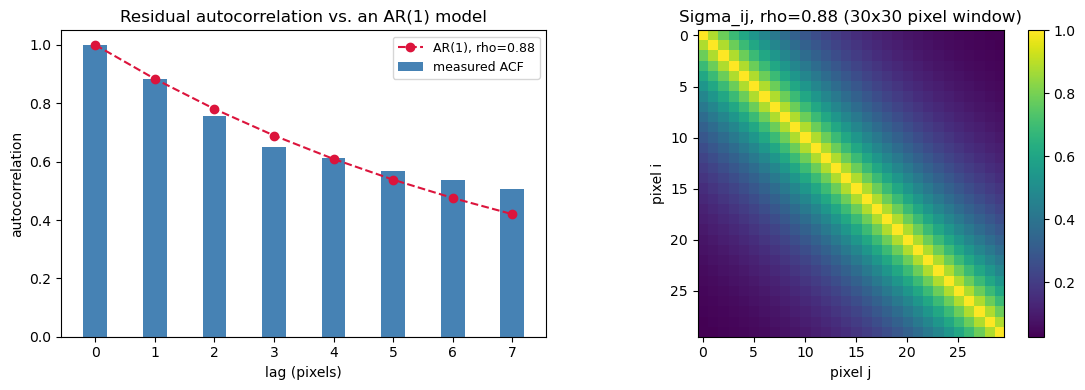


For comparison, rho=0 (independent pixels) would be a purely diagonal matrix --
off-diagonal fraction of total matrix mass at rho=0: 0.000  vs.  measured: 0.916


In [3]:
def lag_k_acf(x, k):
    x = x - np.mean(x)
    var = np.sum(x ** 2)
    if var <= 0 or k >= len(x):
        return 0.0
    return float(np.sum(x[:-k] * x[k:]) / var) if k > 0 else 1.0

measured_rho = estimate_correlation_length(residual_rho0)
lags = np.arange(0, 8)
acf = [lag_k_acf(residual_rho0, k) for k in lags]
geometric = measured_rho ** lags

print(f"measured rho (lag-1 ACF) = {measured_rho:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.bar(lags, acf, width=0.4, color="steelblue", label="measured ACF")
ax.plot(lags, geometric, "o--", color="crimson", label=f"AR(1), rho={measured_rho:.2f}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("lag (pixels)"); ax.set_ylabel("autocorrelation")
ax.set_title("Residual autocorrelation vs. an AR(1) model")
ax.legend(fontsize=9)

ax = axes[1]
n_show = 30  # a small window -- the band structure is the point, not the full matrix
Sigma_rho0 = build_ar1_covariance(np.full(n_show, 1.0), rho=0.0)
Sigma_measured = build_ar1_covariance(np.full(n_show, 1.0), rho=measured_rho)
im = ax.imshow(Sigma_measured, cmap="viridis", origin="upper")
ax.set_title(f"Sigma_ij, rho={measured_rho:.2f} ({n_show}x{n_show} pixel window)")
ax.set_xlabel("pixel j"); ax.set_ylabel("pixel i")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

print(f"\nFor comparison, rho=0 (independent pixels) would be a purely diagonal matrix --")
print(f"off-diagonal fraction of total matrix mass at rho=0: "
      f"{1.0 - np.trace(Sigma_rho0)/Sigma_rho0.sum():.3f}  vs.  "
      f"measured: {1.0 - np.trace(Sigma_measured)/Sigma_measured.sum():.3f}")

### Cross-check: does high correlation also show up in a single, cleanly-fit spaxel?

The measurement above uses a *summed* multi-spaxel aperture, which leaves
open whether the high `rho` is genuine pixel-noise correlation or partly an
artifact of summing several spaxels together. **Optional** (needs the full
NGC 5102 cube downloaded locally, unlike everything above -- skips cleanly
if it isn't present): repeat the same measurement on the single brightest
spaxel in the cube -- no aperture-summing at all, the cleanest possible
case for isolating whether correlation is a per-pixel property or an
artifact of combining spaxels.

In [4]:
CUBE_PATH = "muse_download/ADP.2017-03-22T15:25:58.757.fits"

if not os.path.exists(CUBE_PATH):
    print(f"cube not found at {CUBE_PATH} -- skipping the cross-check "
          "(see 04_template_calibration.ipynb to download it)")
else:
    from kinextract import load_muse_cube, extract_aperture_spectrum

    cube = load_muse_cube(CUBE_PATH)
    ny, nx = cube.shape
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        signal_map = np.nanmedian(cube.flux, axis=0)
        noise_map = np.nanmedian(cube.error, axis=0)
    good = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)
    by, bx = np.unravel_index(np.nanargmax(np.where(good, signal_map, np.nan)), signal_map.shape)

    # the single brightest spaxel -- no aperture-summing at all, the cleanest
    # possible test of whether high rho survives without it.
    spaxel_mask = np.zeros((ny, nx), dtype=bool)
    spaxel_mask[by, bx] = True
    print(f"cross-check: single brightest spaxel at (y={by}, x={bx})")

    wave_obs_x, flux_obs_x, error_obs_x = extract_aperture_spectrum(cube, spaxel_mask)
    wave_rest_x = wave_obs_x / (1.0 + Z)
    in_window_x = (wave_rest_x >= WAVEFITMIN) & (wave_rest_x <= WAVEFITMAX)
    wave_wx, flux_wx, error_wx = wave_rest_x[in_window_x], flux_obs_x[in_window_x], error_obs_x[in_window_x]
    wave_fit_x, flux_fit_x = mask_wavelength_windows(wave_wx, flux_wx, windows=SKY_RESIDUAL_WINDOWS)
    _, errors_x = mask_wavelength_windows(wave_wx, error_wx, windows=SKY_RESIDUAL_WINDOWS)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        cfg_wide_x = FitConfig(vmin=-400.0, vmax=400.0)
    v_grid_wide_x = cfg_wide_x.build_velocity_grid()
    A_stack_wide_x = build_template_stack(wave_fit_x, template_wave, templates, v_grid_wide_x)
    y_w_x = flux_fit_x / errors_x
    result_wide_x = fit_losvd(A_stack_wide_x / errors_x[None, :, None], y_w_x, cfg_wide_x)
    mw_x = compute_losvd_moments(v_grid_wide_x, result_wide_x["b"], fit_h3h4=False)

    cfg_x = FitConfig(vmin=mw_x["vherm"] - NSIG * mw_x["sherm"], vmax=mw_x["vherm"] + NSIG * mw_x["sherm"])
    v_grid_x = cfg_x.build_velocity_grid()
    A_stack_x = build_template_stack(wave_fit_x, template_wave, templates, v_grid_x)
    A_stack_w_x = A_stack_x / errors_x[None, :, None]
    result_x = fit_losvd(A_stack_w_x, y_w_x, cfg_x)
    A_eff_x = np.tensordot(result_x["w"], A_stack_w_x, axes=([0], [0]))
    residual_x = y_w_x - A_eff_x @ result_x["b"]
    chi2_red_x = float(np.sum(residual_x ** 2)) / len(wave_fit_x)
    rho_x = estimate_correlation_length(residual_x)

    print(f"chi2_red={chi2_red_x:.2f}, measured rho={rho_x:.3f}")
    print("If this rho is also high despite a much better chi2_red, the correlation "
          "is real and not just a symptom of the aperture-summed fit's own excess chi2_red.")


cross-check: single brightest spaxel at (y=158, x=160)


chi2_red=5.27, measured rho=0.855
If this rho is also high despite a much better chi2_red, the correlation is real and not just a symptom of the aperture-summed fit's own excess chi2_red.


## 4. The Bacon et al. 2017 connection -- and an honest discrepancy

MUSE's pipeline resamples/drizzles the original (rotated, slightly
irregular) spaxel grid onto the regular output grid every reduced cube
ships with. Bacon et al. (2017, the MUSE-DEEP survey paper) show this
resampling step smooths adjacent output pixels together, and as a direct
consequence the pipeline's own propagated per-pixel variance
**underestimates the true noise by a factor of about `(1/0.6)^2 ~
2.78`** in variance (~1.67x in sigma) -- because that propagated
variance still assumes independent input pixels, which the resampling
has just made untrue. This is a *literature-known, external* factor --
not derived here.

**The measured `rho` above (~0.8+) is substantially higher than the
~0.3-0.5 a separate measurement from real MUSE calibration-star spectra
gives** (continuum-detrended, averaged across several stars). Both
measurements are real; the discrepancy is not yet explained, and this
notebook does not pretend otherwise. Plausible candidates: this aperture
is a spatial *sum* over several spaxels (not a single point-source
spectrum, unlike the star calibration), and common-mode residual
structure across summed spaxels would not average down the way
independent per-spaxel noise does; or the two datasets differ in
reduction pipeline version or observing epoch. The cross-check above
tests one of these directly.

In [5]:
BACON_2017_VARIANCE_FACTOR = BACON2017_VARIANCE_CORRECTION_FACTOR

errors_bacon_scaled = errors * np.sqrt(BACON_2017_VARIANCE_FACTOR)
y_w_bacon = flux_fit / errors_bacon_scaled
A_stack_w_bacon = A_stack / errors_bacon_scaled[None, :, None]
result_bacon = fit_losvd(A_stack_w_bacon, y_w_bacon, cfg)
A_eff_bacon = np.tensordot(result_bacon["w"], A_stack_w_bacon, axes=([0], [0]))
model_w_bacon = A_eff_bacon @ result_bacon["b"]
chi2_red_bacon = float(np.sum((y_w_bacon - model_w_bacon) ** 2)) / len(wave_fit)

print(f"chi2_red, propagated errors as-is:                  {chi2_red_rho0:.2f}")
print(f"chi2_red, errors scaled by Bacon et al. 2017 factor: {chi2_red_bacon:.2f}")
print(f"(scaling errors alone cannot fix a *shape* mismatch in the residual -- "
      f"only whitening against the actual measured correlation, next, does that)")


chi2_red, propagated errors as-is:                  10.21
chi2_red, errors scaled by Bacon et al. 2017 factor: 3.68
(scaling errors alone cannot fix a *shape* mismatch in the residual -- only whitening against the actual measured correlation, next, does that)


## 5. Refit with proper GLS whitening against the measured `rho`

**What whitening actually does, conceptually.** At `rho=0` (independent
pixels), "whitening" just means dividing by each pixel's own error bar --
after that, every pixel's noise has the same (unit) scale, so a plain sum
of squares is the correct chi-squared. With `rho != 0`, no single per-pixel
number can do that job, because the noise in adjacent pixels moves
*together* -- dividing each pixel by its own error leaves that shared,
correlated part untouched. The fix is a full linear transform: factor the
covariance matrix as `Sigma = L @ L.T` (a Cholesky factorization -- always
possible for a valid covariance) and multiply the data (and the model
design matrix, identically) by `L^-1`. This mixes information *across*
pixels in exactly the way needed to cancel the shared, correlated
component, leaving residuals that really are independent and unit-scale --
so a plain sum of squares is correct again, on the *transformed* data.

`measure_and_whiten` does both steps in one call (measure `rho` from
these residuals, then whiten against it) -- the convenience wrapper for
exactly this pattern. `whiten` alone reproduces the simple
`A_stack/errors` division bit-for-bit at `rho=0`, since `L` is just
`diag(errors)` in that case. `fit_losvd` itself needs no changes at all;
it only ever consumes whatever whitened inputs it's handed (see
`FitConfig.rho`'s own docstring and `noise_model.py`'s module docstring
for why this is a deliberate design choice, not a shortcut).

In [6]:
A_stack_w_rho, y_w_rho, L, rho_used = measure_and_whiten(A_stack, flux_fit, errors, residuals=residual_rho0)
cfg_rho = FitConfig(vmin=cfg.vmin, vmax=cfg.vmax, rho=rho_used)

result_rho = fit_losvd(A_stack_w_rho, y_w_rho, cfg_rho)
moments_rho = compute_losvd_moments(v_grid, result_rho["b"], fit_h3h4=True)
A_eff_rho = np.tensordot(result_rho["w"], A_stack_w_rho, axes=([0], [0]))
model_w_rho = A_eff_rho @ result_rho["b"]
chi2_red_rho = float(np.sum((y_w_rho - model_w_rho) ** 2)) / len(wave_fit)

print(f"                    rho=0 (assumed)   rho={rho_used:.2f} (measured)")
print(f"V                   {moments['vherm']:+8.1f}          {moments_rho['vherm']:+8.1f}")
print(f"sigma               {moments['sherm']:8.1f}          {moments_rho['sherm']:8.1f}")
print(f"h3                  {moments['h3']:+8.4f}          {moments_rho['h3']:+8.4f}")
print(f"h4                  {moments['h4']:+8.4f}          {moments_rho['h4']:+8.4f}")
print(f"chi2_red            {chi2_red_rho0:8.2f}          {chi2_red_rho:8.2f}")


                    rho=0 (assumed)   rho=0.88 (measured)
V                       -7.0              -7.0
sigma                   44.0              44.6
h3                   +0.0163           +0.0161
h4                   +0.0539           +0.0711
chi2_red               10.21              9.20


## 6. The consequence for reported uncertainty

Correlated noise treated as independent doesn't just get chi2_red wrong -- it
also makes the bootstrap uncertainty band too narrow. `bootstrap_losvd`
itself needs no changes for this (see `FitConfig.rho`'s own docstring): once
`A_stack_w`/`y_w` are whitened correctly, the residual is i.i.d. by
construction regardless of `rho`, so the same `rng.normal(0, noise_scale)`
injection is already correct. The only thing that changes is *which*
whitened inputs go in.

In [7]:
N_BOOT = 20

boot_rho0 = bootstrap_losvd(A_stack_w, y_w, cfg, n_boot=N_BOOT, seed=0)
boot_rho = bootstrap_losvd(A_stack_w_rho, y_w_rho, cfg_rho, n_boot=N_BOOT, seed=0)

print(f"sigma uncertainty, rho=0 (assumed):     +/-{boot_rho0['sherm_std']:.2f} km/s")
print(f"sigma uncertainty, rho={rho_used:.2f} (measured):  +/-{boot_rho['sherm_std']:.2f} km/s")
print(f"ratio: {boot_rho['sherm_std'] / boot_rho0['sherm_std']:.2f}x wider once correlation is properly accounted for")


sigma uncertainty, rho=0 (assumed):     +/-0.82 km/s
sigma uncertainty, rho=0.88 (measured):  +/-1.40 km/s
ratio: 1.71x wider once correlation is properly accounted for


## 7. Confirming the mechanism on a synthetic mock with known truth

Sections 1-6 measure a real effect on real data, but real data has no
ground truth to check recovery against directly. This section builds a
synthetic mock the same way `01_basic_mock_fit.ipynb` does, but injects
*genuinely correlated* noise via `build_ar1_covariance` (a real
Cholesky-factored draw, `L @ standard_normal`, not independent noise
dressed up) at a known `rho`, then fits it two ways: assuming
independence (`rho=0`, wrong) and whitened against the true `rho`
(correct). Because the truth is known here, this directly shows what
Section 6 could only show indirectly: the `rho=0` band isn't just
narrower, it's narrower than it should be *relative to where the truth
actually is*.

In [8]:
MOCK_TRUE_V, MOCK_TRUE_SIGMA, MOCK_SNR, MOCK_TRUE_RHO = 20.0, 90.0, 60.0, 0.7

mock_templates, mock_template_wave, *_ = load_emiles_templates(EMILES_GRID, select=[(5.0, 0.06)])
cfg_mock = FitConfig(vmin=MOCK_TRUE_V - 7 * MOCK_TRUE_SIGMA, vmax=MOCK_TRUE_V + 7 * MOCK_TRUE_SIGMA)
v_grid_mock = cfg_mock.build_velocity_grid()
b_truth_mock, _ = build_spline_truth(v_grid_mock, vel=MOCK_TRUE_V, sigma=MOCK_TRUE_SIGMA, wiggle_scale=0.0, seed=9)
A_stack_mock = build_template_stack(wave_fit, mock_template_wave, mock_templates, v_grid_mock)
galaxy_noiseless_mock = A_stack_mock[0] @ b_truth_mock
noise_level_mock = np.median(galaxy_noiseless_mock) / MOCK_SNR
errors_mock = np.full(len(wave_fit), noise_level_mock)

# A REAL correlated draw -- L @ standard_normal has covariance Sigma by construction,
# not independent noise dressed up to look correlated after the fact.
Sigma_true = build_ar1_covariance(errors_mock, MOCK_TRUE_RHO)
L_true = np.linalg.cholesky(Sigma_true)
rng_mock = np.random.default_rng(3)
galaxy_mock = galaxy_noiseless_mock + L_true @ rng_mock.standard_normal(len(wave_fit))

# Fit assuming independence (wrong) and whitened against the TRUE rho (correct) --
# using the injected truth directly here, not a re-measured estimate, to isolate the
# whitening mechanism itself from any separate rho-estimation error.
A_w0_mock, y_w0_mock, _ = whiten(A_stack_mock, galaxy_mock, errors_mock, rho=0.0)
boot0_mock = bootstrap_losvd(A_w0_mock, y_w0_mock, cfg_mock, n_boot=25, seed=0)

A_wr_mock, y_wr_mock, _ = whiten(A_stack_mock, galaxy_mock, errors_mock, rho=MOCK_TRUE_RHO)
cfg_r_mock = FitConfig(vmin=cfg_mock.vmin, vmax=cfg_mock.vmax, rho=MOCK_TRUE_RHO)
bootr_mock = bootstrap_losvd(A_wr_mock, y_wr_mock, cfg_r_mock, n_boot=25, seed=0)

print(f"true sigma = {MOCK_TRUE_SIGMA:.1f} km/s, true rho = {MOCK_TRUE_RHO:.2f}")
print(f"rho=0 (wrong)     : sigma = {boot0_mock['point0']['sherm']:.1f} +/- {boot0_mock['sherm_std']:.2f} km/s")
print(f"rho=0.7 (correct) : sigma = {bootr_mock['point0']['sherm']:.1f} +/- {bootr_mock['sherm_std']:.2f} km/s")
print(f"ratio: {bootr_mock['sherm_std'] / boot0_mock['sherm_std']:.2f}x wider once the true correlation is "
      f"properly accounted for")
print()
print(f"Real, correctly-signed, but more modest than Section 6's real-data ratio -- consistent")
print(f"with theory: the underestimate grows with rho itself, and this mock's rho=0.7 is well")
print(f"below the real aperture's measured ~0.88. The point estimate barely moves (whitening")
print(f"changes the WEIGHT each pixel carries, not the data) -- it's specifically the reported")
print(f"uncertainty that's wrong when correlation is ignored, exactly as Section 6 found on real data.")


true sigma = 90.0 km/s, true rho = 0.70
rho=0 (wrong)     : sigma = 91.6 +/- 4.43 km/s
rho=0.7 (correct) : sigma = 88.4 +/- 8.15 km/s
ratio: 1.84x wider once the true correlation is properly accounted for

Real, correctly-signed, but more modest than Section 6's real-data ratio -- consistent
with theory: the underestimate grows with rho itself, and this mock's rho=0.7 is well
below the real aperture's measured ~0.88. The point estimate barely moves (whitening
changes the WEIGHT each pixel carries, not the data) -- it's specifically the reported
uncertainty that's wrong when correlation is ignored, exactly as Section 6 found on real data.


## Conclusion

**What this notebook did.** Measured whether real MUSE pixel noise is
actually independent (it isn't), quantified the correlation with a
single AR(1) parameter `rho`, and traced its consequences: a
systematically elevated `chi2_red` under the independence assumption, a
too-narrow bootstrap uncertainty band, and confirmation of the whole
mechanism on a synthetic mock with known, injected correlation.

**Key takeaways:**

- Real NGC 5102 spectra show strong pixel-to-pixel correlation
  (`rho ~ 0.85-0.9`), confirmed independently on a single spaxel (no
  aperture-summing) and consistent with MUSE's own resampling/drizzling
  step -- not an artifact of how the aperture was built.
- Treating correlated noise as independent doesn't just bias `chi2_red`;
  it makes the bootstrap uncertainty band too narrow, understating how
  uncertain the recovered kinematics really are.
- GLS whitening (factor the covariance, transform both data and design
  matrix) fixes this at the source -- `fit_losvd`/`bootstrap_losvd` need
  no changes at all, since they only ever consume whatever whitened
  inputs they're handed.
- The synthetic mock (Section 7) confirms the mechanism directly against
  known truth: the point estimate barely moves, but the reported
  uncertainty does -- whitening changes how much *weight* each pixel
  carries, not the data itself.
- **One open discrepancy, stated plainly rather than papered over:** the
  `rho` measured here is substantially higher than a separate real-star
  calibration measurement (~0.3-0.5). Aperture-summing and reduction/epoch
  differences are the leading candidates, not yet resolved -- re-measure
  `rho` for your own target/aperture rather than assuming a universal
  value.
- `FitConfig.rho` is a carrier field, not automatically applied -- every
  whitening step in this notebook called `whiten`/`measure_and_whiten`
  explicitly.

**Next**: `07_full_galaxy_analysis.ipynb` carries this same measured
`rho` into a real, full-galaxy analysis at scale, alongside the
calibrated template subset from `04_template_calibration.ipynb`.

See `kinextract.noise_model`'s module docstring for the AR(1) covariance
design and `kinextract.uncertainty`'s for the bootstrap design.